# Wielokatalogowe wyznaczanie odległości i analiza utraty informacji (`IC 434`)

Autor: **Kacper Kania** ([@kacperkan](https://github.com/kacperkan))

Notatnik realizuje dla pola wokół mgławicy **IC 434** ($\text{RA}=85.25^\circ, \text{Dec}=-2.45^\circ, r=0.35^\circ$, kompleks $\sigma$ Orionis / Koński Łeb, $d \approx 395\text{ pc}$):

1. **Wielokatalogowy cross-match (12 katalogów astronomicznych)**: połączenie po `source_id` oraz współrzędnych $(\text{RA}, \text{Dec})$ przy użyciu `match_coordinates_sky` ($r \le 2.0''$) danych z:
   - **Gaia DR3** (`gaiadr3.gaia_source`: astrometria $\varpi, \mu_\alpha^*, \mu_\delta$, fotometria $G, G_{\text{BP}}, G_{\text{RP}}$, prędkość radialna $v_{\text{rad}}$)
   - **Bailer-Jones EDR3/DR3** (`external.gaiaedr3_distance`: bayesowskie odległości `r_med_geo`, `r_med_photogeo`)
   - **Gaia DR3 GSP-Phot & MSC** (`gaiadr3.astrophysical_parameters`: $T_{\text{eff}}, \log g, [\text{M/H}], A_0, E(BP-RP), R, d_{\text{GSP-Phot}}, d_{\text{MSC}}$)
   - **Gaia DR3 FLAME** (`gaiadr3.astrophysical_parameters`: jasność bolometryczna $L_{\text{FLAME}}$, promień $R_{\text{FLAME}}$, masa $M_{\text{FLAME}}$, wiek)
   - **Gaia DR3 XP Synthetic Photometry** (`gaiadr3.synthetic_photometry_gspc`: pasma $B, V, I$ Johnsona-Cousinsa oraz $g, r, i$ SDSS z widm niskiej rozdzielczości BP/RP)
   - **2MASS Point Source Catalog** (`IRSA fp_psc`: bliska podczerwień $J, H, K_s$)
   - **AllWISE** (`IRSA allwise_p3as_psd`: średnia podczerwień $W1, W2, W3, W4$)
   - **CatWISE2020** (`external.catwise2020`: fotometria $W1_{\text{PM}}, W2_{\text{PM}}$ oraz ruchy własne w podczerwieni)
   - **APASS DR9** (`external.apassdr9`: fotometria optyczna $V, B, B-V, g', r', i'$)
   - **SDSS DR13** (`external.sdssdr13_photoprimary`: fotometria wielopasmowa $u, g, r, i, z$)
   - **LAMOST DR9 + Pan-STARRS1** (`external.lamost_dr9_lrs`, `gaiadr3.panstarrs1_best_neighbour`: spektroskopia $z_{\text{spec}}$ oraz pasma $g, r, i, z, y$)
   - **Tycho-2 & Hipparcos-2** (`public.tycho2`, `public.hipparcos_newreduction`: jasne gwiazdy $B_T, V_T, H_p, \varpi_{\text{Hip}}$)
2. **Ranking braków danych (absence rate) i ważności cech (importance)**: ile procent gwiazd w polu IC 434 nie posiada danego parametru oraz ile bitów informacji wnosi dana grupa cech dla pojedynczego punktu.
3. **Stopniowe usuwanie danych z pojedynczego punktu (progresywna ablacja)**: ile informacji o odległości tracimy, odrzucając kolejne parametry — zaczynając od **najczęściej brakujących** i sortując według **ważności**, aż do pozostawienia wyłącznie samych współrzędnych $(\text{RA}, \text{Dec})$.

## 1. Złączenie 12 katalogów wokół IC 434 (`source_id` + `match_coordinates_sky`)

Pobieramy dane z serwerów TAP (ESA Gaia oraz NASA/IPAC IRSA) w stożku $r = 0.35^\circ$ wokół **IC 434** ($\text{RA}=85.25^\circ, \text{Dec}=-2.45^\circ$) i zapisujemy połączoną tabelę lokalnie w `data/ic434_multicatalog.csv`.

In [1]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from catalogs import fetch_all_catalogs, load_multicatalog_dataset

plt.rcParams.update({"figure.dpi": 120, "axes.grid": True, "grid.alpha": 0.25})

SAMPLE_NAME = "IC 434"
RA0, DEC0, RADIUS_DEG = 85.25, -2.45, 0.35
CACHE_PATH = "data/ic434_multicatalog.csv"

if os.path.exists(CACHE_PATH):
    df = load_multicatalog_dataset(CACHE_PATH)
else:
    df, _ = fetch_all_catalogs(RA0, DEC0, RADIUS_DEG, 500)

catalog_coverage = pd.DataFrame([
    {"Catalog": "1. Gaia DR3 (Core Astrometry & G/BP/RP, RUWE<1.4)", "Matched": int(df["phot_g_mean_mag"].notna().sum())},
    {"Catalog": "2. Bailer-Jones EDR3/DR3 (r_med_geo / r_med_photogeo)", "Matched": int(df["r_med_photogeo"].notna().sum())},
    {"Catalog": "3. 2MASS PSC (J, H, Ks Near-IR)", "Matched": int(df["j_m"].notna().sum())},
    {"Catalog": "4. Gaia DR3 XP Synthetic Photometry (JKC & SDSS bands)", "Matched": int((df["v_jkc_mag"].notna() | df["r_sdss_mag"].notna()).sum())},
    {"Catalog": "5. AllWISE (W1-W4 Mid-IR)", "Matched": int(df["w1mpro"].notna().sum())},
    {"Catalog": "6. Gaia DR3 GSP-Phot & MSC (Teff, logg, [M/H], A0, d_MSC)", "Matched": int((df["teff_gspphot"].notna() | df["distance_msc"].notna()).sum())},
    {"Catalog": "7. CatWISE2020 (W1/W2 + IR Proper Motions)", "Matched": int(df["w1mpro_pm"].notna().sum())},
    {"Catalog": "8. Gaia DR3 FLAME (Stellar Luminosity, Radius, Mass)", "Matched": int((df["lum_flame"].notna() | df["mass_flame"].notna()).sum())},
    {"Catalog": "9. APASS DR9 (Optical V, B, g', r', i')", "Matched": int((df["apass_vmag"].notna() | df["apass_r_mag"].notna()).sum())},
    {"Catalog": "10. SDSS DR13 (Optical u, g, r, i, z)", "Matched": int(df["sdss_r"].notna().sum())},
    {"Catalog": "11. LAMOST DR9 + Pan-STARRS1 (Spectroscopy + grizy)", "Matched": int((df["lamost_z"].notna() | df["mag_ps_r"].notna()).sum())},
    {"Catalog": "12. Tycho-2 & Hipparcos-2 (BT, VT, Hp, plx_Hip)", "Matched": int((df["vt_mag"].notna() | df["hp_mag"].notna()).sum())},
])
catalog_coverage["Present_%"] = (catalog_coverage["Matched"] / len(df) * 100).round(1)
catalog_coverage["Absent_%"] = (100.0 - catalog_coverage["Present_%"]).round(1)
catalog_coverage

,Catalog,Matched,Present_%,Absent_%
0,"1. Gaia DR3 (Core Astrometry & G/BP/RP, RUWE<1.4)",512,100.0,0.0
1,2. Bailer-Jones EDR3/DR3 (r_med_geo / r_med_ph...,512,100.0,0.0
2,"3. 2MASS PSC (J, H, Ks Near-IR)",506,98.8,1.2
3,4. Gaia DR3 XP Synthetic Photometry (JKC & SDS...,481,93.9,6.1
4,5. AllWISE (W1-W4 Mid-IR),484,94.5,5.5
5,"6. Gaia DR3 GSP-Phot & MSC (Teff, logg, [M/H],...",475,92.8,7.2
6,7. CatWISE2020 (W1/W2 + IR Proper Motions),362,70.7,29.3
7,"8. Gaia DR3 FLAME (Stellar Luminosity, Radius,...",269,52.5,47.5
8,"9. APASS DR9 (Optical V, B, g', r', i')",215,42.0,58.0
9,"10. SDSS DR13 (Optical u, g, r, i, z)",112,21.9,78.1


### Wizualizacja wielokatalogowego cross-matchu w polu IC 434

Porównujemy pokrycie 12 katalogów, rozkład odległości wzdłuż linii widzenia (z wyraźnym pikiem kompleksu **IC 434 / $\sigma$ Orionis** przy $\sim 395\text{ pc}$) oraz zgodność niezależnych estymatorów odległości z katalogów (`r_med_photogeo`, `r_med_geo`, $1000/\varpi$, `distance_gspphot`, `distance_msc`).

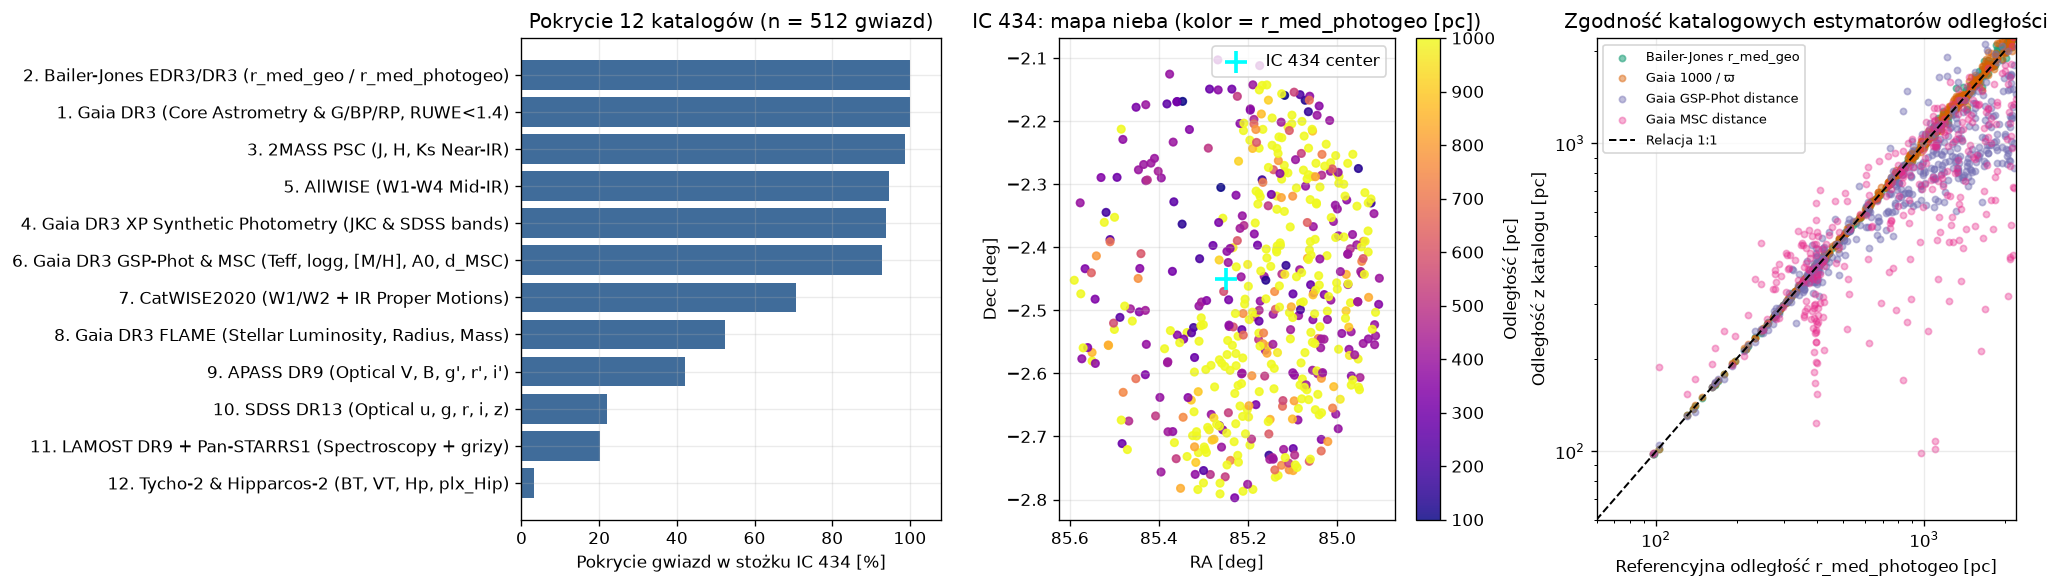

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5.0))

cov_sorted = catalog_coverage.sort_values("Present_%", ascending=True)
axes[0].barh(cov_sorted["Catalog"], cov_sorted["Present_%"], color="#2b5c8f", alpha=0.9)
axes[0].set_xlabel("Pokrycie gwiazd w stożku IC 434 [%]")
axes[0].set_title(f"Pokrycie 12 katalogów (n = {len(df)} gwiazd)")
axes[0].set_xlim(0, 108)

sc = axes[1].scatter(df["ra"], df["dec"], c=np.clip(df["r_med_photogeo"], 100, 1000), cmap="plasma", s=20, alpha=0.85)
axes[1].scatter(RA0, DEC0, marker="+", s=170, c="cyan", lw=2.2, label="IC 434 center")
axes[1].invert_xaxis()
axes[1].set_xlabel("RA [deg]")
axes[1].set_ylabel("Dec [deg]")
axes[1].set_title("IC 434: mapa nieba (kolor = r_med_photogeo [pc])")
axes[1].legend(loc="upper right")
plt.colorbar(sc, ax=axes[1], label="Odległość [pc]")

axes[2].scatter(df["r_med_photogeo"], df["r_med_geo"], s=14, alpha=0.55, label="Bailer-Jones r_med_geo", color="#1b9e77")
axes[2].scatter(df["r_med_photogeo"], df["d_naive_pc"], s=14, alpha=0.45, label="Gaia 1000 / ϖ", color="#d95f02")
axes[2].scatter(df["r_med_photogeo"], df["distance_gspphot"], s=14, alpha=0.45, label="Gaia GSP-Phot distance", color="#7570b3")
axes[2].scatter(df["r_med_photogeo"], df["distance_msc"], s=14, alpha=0.35, label="Gaia MSC distance", color="#e7298a")
axes[2].plot([50, 2000], [50, 2000], "k--", lw=1.2, label="Relacja 1:1")
axes[2].set_xscale("log")
axes[2].set_yscale("log")
axes[2].set_xlim(60, 2200)
axes[2].set_ylim(60, 2200)
axes[2].set_xlabel("Referencyjna odległość r_med_photogeo [pc]")
axes[2].set_ylabel("Odległość z katalogu [pc]")
axes[2].set_title("Zgodność katalogowych estymatorów odległości")
axes[2].legend(fontsize=8)

plt.tight_layout()
plt.show()

## 2. Brakujące parametry vs ważność informacyjna i progresywne usuwanie cech

Badamy predykcję odległości $\log_{10}(d)$ (gdy dla badanego punktu nie mamy bezpośredniej paralaksy) na podstawie **15 grup parametrów** pochodzących z 12 połączonych katalogów:
- Każda grupa parametrów ma naturalny **odsetek braków (`Absent_%`)** w polu IC 434 (od $96.9\%$ braków dla Tycho-2/Hipparcos i $79.4\%$ dla spektroskopii LAMOST aż do $0\%$ dla optyki i pozycji Gaia).
- Dla pojedynczego punktu mierzymy **ważność informacyjną grupy (`Importance_dex` / bity informacji)** jako wzrost błędu predykcji po jej usunięciu.
- Następnie przeprowadzamy **progresywne usuwanie cech z pojedynczego punktu** w dwóch wariantach:
  1. **Od najczęściej brakujących (posortowane wg ważności w warstwach dostępności)** — odpowiada realnemu ubożeniu katalogów od rzadkich przeglądów spektroskopowych/historycznych do samych współrzędnych $(\text{RA}, \text{Dec})$.
  2. **Czysto według ważności (od najmniej do najbardziej istotnych cech)** — dolne ograniczenie utraty informacji przy kompresji cech.

In [3]:
from estimators import predict_knn_subspace, prepare_regression_state, run_progressive_ablation

state = prepare_regression_state(df, seed=42)
y_all = state["y_all"]
test_idx = state["test_idx"]

ablation_df, ordered_groups_df = run_progressive_ablation(state, k=12)
records = list(ordered_groups_df.to_dict("records"))

preds_by_step, stds_by_step = [], []
for step in range(len(records)):
    active_cols = [c for g in records[step:] for c in g["Cols"]]
    _, _, _, pred_logd, pred_std, _ = predict_knn_subspace(state, active_cols, k=12)
    preds_by_step.append(pred_logd)
    stds_by_step.append(pred_std)

ablation_df

2026-11-19 18:50:04.175 | INFO     | estimators:prepare_regression_state:285 - Measurement errors available for 15469/26112 feature observations; unknown errors unweighted for k-NN, omitted for XD


Output()

,Step,Groups_Remaining,Removed_Parameter_Group,Removed_Absent_%,MAE_dex,RMSE_dex,Median_Rel_Error_%,Info_Lost_bits,KL_Info_Gain_bits,KL_Change_bits
0,0,15,None (Full 15-group / 14-catalog vector),0.0,0.1189,0.1585,20.90,0.000,1.066746,NaN
1,1,14,"Tycho-2 / Hipparcos (BT, VT, Hp)",96.7,0.1188,0.1585,20.68,0.000,1.066879,0.000132
2,2,13,"LAMOST DR9 + PS1 (z_spec, g, r, i)",79.7,0.1186,0.1583,20.90,0.000,1.067291,0.000412
3,3,12,"SDSS DR13 Optical (u, g, r, i, z)",78.1,0.1182,0.1579,20.90,0.000,1.067188,-0.000103
4,4,11,"APASS DR9 Optical (V, B, g', r', i')",57.2,0.1176,0.1571,20.90,0.000,1.063383,-0.003805
5,5,10,Gaia Radial Velocity (v_rad),77.3,0.1187,0.1594,20.80,0.008,1.053131,-0.010252
6,6,9,"CatWISE2020 (W1_pm, W2_pm, PM_IR)",29.3,0.1199,0.1606,20.77,0.019,1.063254,0.010123
7,7,8,"Gaia FLAME (log L, R, M)",47.5,0.1226,0.1624,21.61,0.035,1.065081,0.001827
8,8,7,"Gaia GSP-Phot (Teff, logg, [M/H], A0, R)",18.0,0.1387,0.1819,24.51,0.198,0.997651,-0.067431
9,9,6,"Gaia XP Synthetic (V_JKC, B_JKC, r_SDSS)",6.1,0.1389,0.1827,25.46,0.205,1.010282,0.012631


## 3. Wizualizacja utraty informacji dla pojedynczego punktu i całej próbki IC 434

Poniższe wykresy pokazują:
1. **Krzywą degradacji dokładności (MAE w dex oraz utrata informacji w bitach)** w miarę odcinania kolejnych grup parametrów (od najczęściej brakujących aż do samych współrzędnych $(\text{RA}, \text{Dec})$).
2. **Trajektorię pojedynczego punktu (Single-Point Degradation Fan)** dla trzech reprezentatywnych gwiazd w stożku IC 434 (gwiazda pierwszego planu $\sim 135\text{ pc}$, członek kompleksu **IC 434 / $\sigma$ Ori** $\sim 395\text{ pc}$ oraz gwiazda tła $\sim 850\text{ pc}$): jak estymowana odległość $\hat{d}$ dryfuje, a przedział niepewności $\pm 1\sigma$ rozszerza się po usunięciu kolejnych danych.
3. **Rozrzut Prawdziwa vs Przewidywana odległość** w czterech kluczowych punktach ablacji.

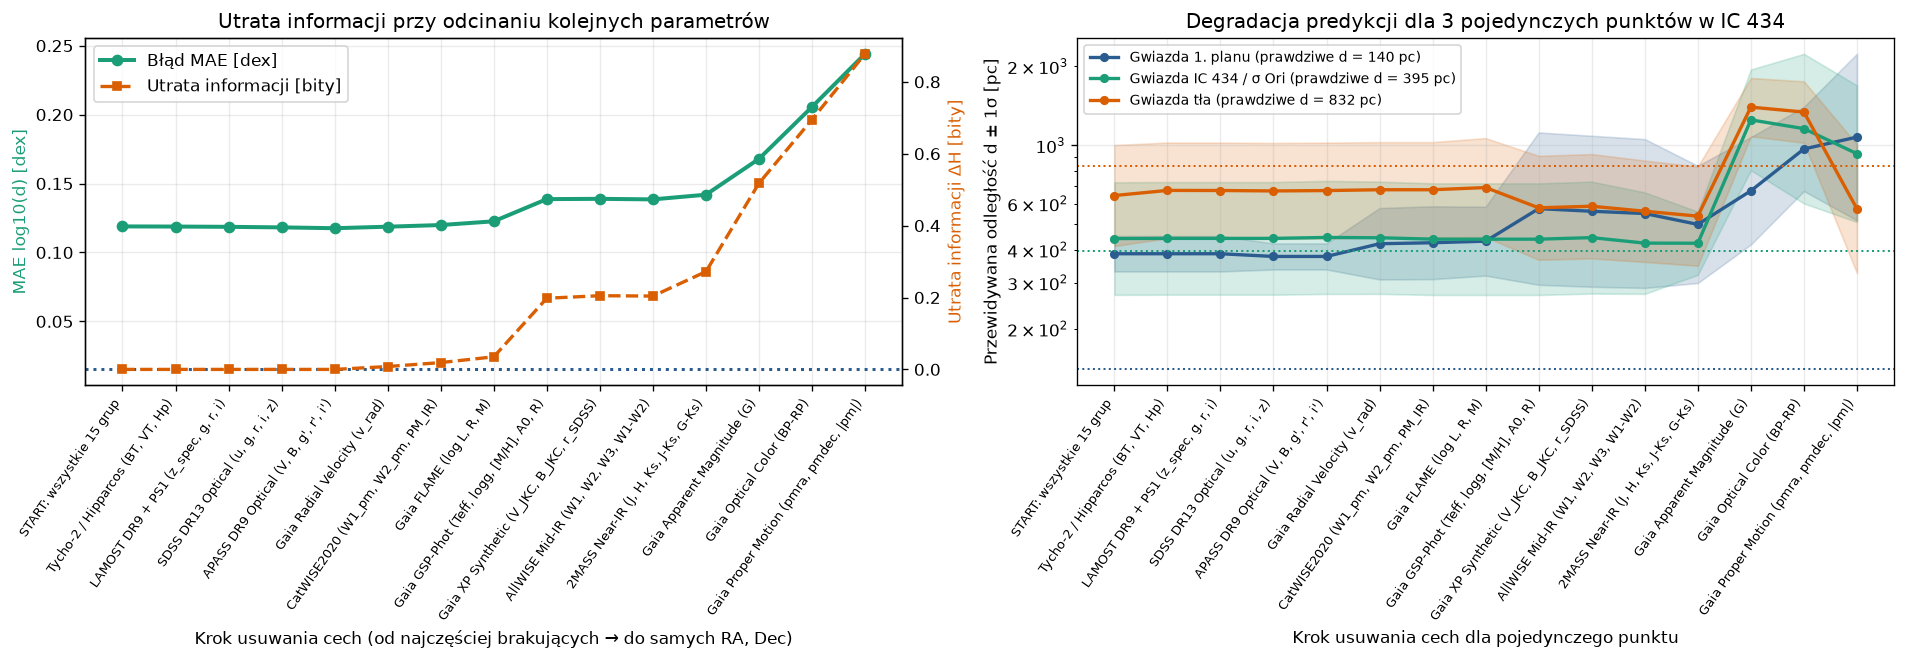

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.6))

steps = ablation_df["Step"].to_numpy()
labels = ["START: wszystkie 15 grup"] + [r.replace("Removed: ", "- ") for r in ablation_df["Removed_Parameter_Group"].iloc[1:]]

ax1 = axes[0]
line1 = ax1.plot(steps, ablation_df["MAE_dex"], "o-", color="#1b9e77", lw=2.4, ms=6, label="Błąd MAE [dex]")
ax1.axhline(0.0152, color="#2b5c8f", ls=":", lw=1.8, label="Cross-match z paralaksą Gaia (0.015 dex)")
ax1.set_xlabel("Krok usuwania cech (od najczęściej brakujących → do samych RA, Dec)")
ax1.set_ylabel("MAE log10(d) [dex]", color="#1b9e77")
ax1.set_xticks(steps)
ax1.set_xticklabels(labels, rotation=55, ha="right", fontsize=8)

ax1b = ax1.twinx()
line2 = ax1b.plot(steps, ablation_df["Info_Lost_bits"], "s--", color="#d95f02", lw=2.0, ms=5, label="Utrata informacji [bity]")
ax1b.set_ylabel("Utrata informacji ΔH [bity]", color="#d95f02")
ax1b.grid(False)
ax1.set_title("Utrata informacji przy odcinaniu kolejnych parametrów")

lines = line1 + line2
ax1.legend(lines, [l.get_label() for l in lines], loc="upper left")

preds_arr = np.array(preds_by_step)
stds_arr = np.array(stds_by_step)
true_test_d = 10 ** y_all[test_idx]

fg_i = int(np.argmin(np.abs(true_test_d - 145.0)))
cl_i = int(np.argmin(np.abs(true_test_d - 395.0)))
bg_i = int(np.argmin(np.abs(true_test_d - 820.0)))

exemplars = [
    (fg_i, "Gwiazda 1. planu", "#2b5c8f"),
    (cl_i, "Gwiazda IC 434 / σ Ori", "#1b9e77"),
    (bg_i, "Gwiazda tła", "#d95f02"),
]

for idx_pt, title_pt, col in exemplars:
    d_med = 10 ** preds_arr[:, idx_pt]
    d_lo = 10 ** (preds_arr[:, idx_pt] - stds_arr[:, idx_pt])
    d_hi = 10 ** (preds_arr[:, idx_pt] + stds_arr[:, idx_pt])
    d_true = true_test_d[idx_pt]
    axes[1].plot(steps, d_med, "o-", color=col, lw=2.0, ms=4.5, label=f"{title_pt} (prawdziwe d = {d_true:.0f} pc)")
    axes[1].fill_between(steps, d_lo, d_hi, color=col, alpha=0.18)
    axes[1].axhline(d_true, color=col, ls=":", lw=1.2)

axes[1].set_yscale("log")
axes[1].set_xticks(steps)
axes[1].set_xticklabels(labels, rotation=55, ha="right", fontsize=8)
axes[1].set_xlabel("Krok usuwania cech dla pojedynczego punktu")
axes[1].set_ylabel("Przewidywana odległość d ± 1σ [pc]")
axes[1].set_title("Degradacja predykcji dla 3 pojedynczych punktów w IC 434")
axes[1].legend(loc="upper left", fontsize=8.5)

plt.tight_layout()
plt.show()

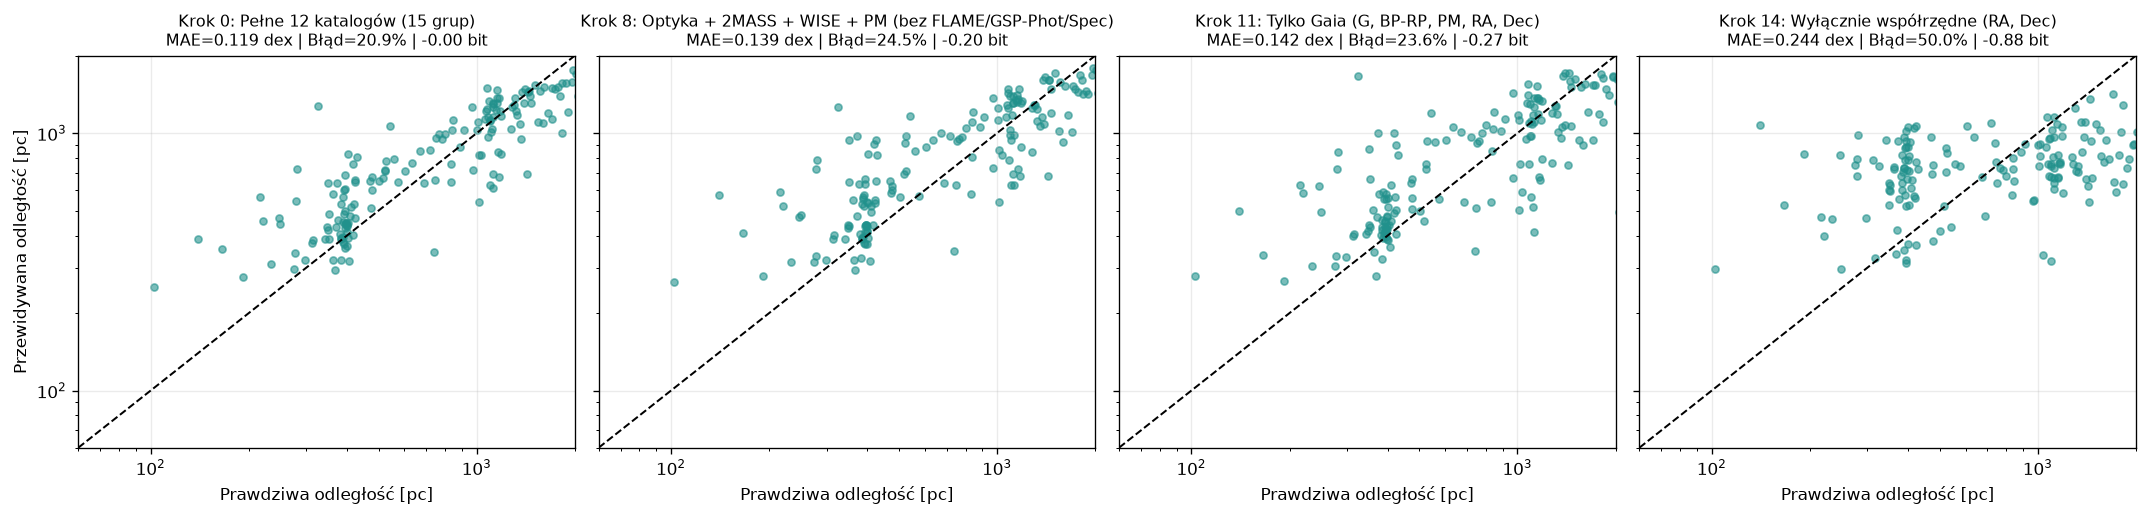

In [5]:
checkpoints = [
    (0, "Krok 0: Pełne 12 katalogów (15 grup)"),
    (8, "Krok 8: Optyka + 2MASS + WISE + PM (bez FLAME/GSP-Phot/Spec)"),
    (11, "Krok 11: Tylko Gaia (G, BP-RP, PM, RA, Dec)"),
    (14, "Krok 14: Wyłącznie współrzędne (RA, Dec)"),
]

fig, axes = plt.subplots(1, 4, figsize=(18, 4.4), sharey=True)
for ax, (st, title_st) in zip(axes, checkpoints):
    pred_d = 10 ** preds_arr[st]
    mae_st = ablation_df.loc[st, "MAE_dex"]
    rel_st = ablation_df.loc[st, "Median_Rel_Error_%"]
    bits_st = ablation_df.loc[st, "Info_Lost_bits"]
    ax.scatter(true_test_d, pred_d, s=18, alpha=0.6, color="#21918c")
    ax.plot([60, 2000], [60, 2000], "k--", lw=1.2)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlim(60, 2000)
    ax.set_ylim(60, 2000)
    ax.set_xlabel("Prawdziwa odległość [pc]")
    ax.set_title(f"{title_st}\nMAE={mae_st:.3f} dex | Błąd={rel_st:.1f}% | -{bits_st:.2f} bit", fontsize=9.5)

axes[0].set_ylabel("Przewidywana odległość [pc]")
plt.tight_layout()
plt.show()